# Microscope feature checks

The executed calculations demonstrate flat illumination, crossover and defocus, objective aberrations, and projector distortion with 220,000–330,000 coherent Gaussians. **One omission remains: the objective astigmatism term is absent exactly on the optical axis.**

| Question | Finding |
|---|---|
| Does a flat field remain flat at focus? | Yes, for the matched source used here. |
| Do crossover and defocus change the detector image? | Yes; the beam contracts at crossover and specimen contrast changes with defocus. |
| Do spherical aberration and astigmatism affect the focal image? | Yes, with the exact-axis omission noted above. |
| Does PL1 produce radial and spiral distortion? | Yes; both signs are checked against a coherent-field reference. |

Read the four image sections first. The numerical comparisons follow at the end, and the [Seidel derivation](seidel_gaussian_action.md) is separate. Run all cells in order; calculation cells are collapsed and can be expanded.

## Calculation settings

The source is constructed to produce a flat specimen field. The calibration pipeline's default Gaussian source is a different illumination condition. Intensities include interference, $I=|\sum_j\psi_j|^2$.

In [1]:
N_BEAMLETS = 220_000
REFINED_BEAMLETS = 330_000
SHAPE = (192, 192)
MAGNIFICATION = 40_000.0
BEAM_RADIUS = 150e-9

In [2]:
from pathlib import Path
from dataclasses import replace
from types import SimpleNamespace
import os
import json
from IPython.display import Markdown, display
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares, brentq
from scipy.ndimage import map_coordinates
from temgym_core.microscope import Microscope, find_imaging_condition
from temgym_core.components import Plane, Lens, Rotator, KrivanekLens, DistortedLens
from temgym_core.aberrations import KrivanekCoeffs
from temgym_core.gaussian import FreeSpacePropagator, make_gaussian
from temgym_core.run import run_to_end, solve_model_with_z, column_matrix
from temgym_core.ray import Ray
from temgym_core.source import circular_input_wave
from temgym_core.evaluate import evaluate_gaussians
from temgym_core.constants import energy2wavelength
from temgym_core.calibration.gaussian import make_magical_sample
%matplotlib inline
repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/temgym_core").is_dir())
METHOD = "spatial" if any(d.platform == "gpu" for d in jax.devices()) else "scan"
results = {}
plt.rcParams.update({"font.size": 11, "axes.titlesize": 11})

def grid(width, shape=SHAPE):
    ax = (np.arange(shape[1]) - (shape[1]-1)/2) * width/shape[1]
    ay = (np.arange(shape[0]) - (shape[0]-1)/2) * width/shape[0]
    xx, yy = np.meshgrid(ax, ay)
    return SimpleNamespace(shape=shape, coords=jnp.asarray(np.c_[xx.ravel(), yy.ravel()]))

def propagate(beam, column):
    return jax.jit(lambda b: run_to_end(b, tuple(column),
        propagator=FreeSpacePropagator(include_axial_path=False)))(beam)

def intensity(beam, g, method=METHOD):
    field = np.asarray(evaluate_gaussians(beam, g, method=method, tile_beams=32))
    assert np.isfinite(field).all(), "Nonfinite coherent field"
    return np.abs(field)**2

def relerr(a, b):
    return float(np.linalg.norm(a-b)/np.linalg.norm(b))

def disk(radius, z, count=N_BEAMLETS):
    waist = radius * 1.5 * np.sqrt(np.pi/count)
    b = circular_input_wave(radius, waist, voltage, z0=z, overlap_factor=1.5)
    assert np.count_nonzero(np.asarray(b.amplitude)) >= count
    return b

def panel(ax, im, width, title, unit="mm", vmax=None):
    scale = {"mm":1e3, "nm":1e9}[unit]
    artist = ax.imshow(im, origin="lower", cmap="inferno",
        extent=np.array([-1,1,-1,1])*width*scale/2, vmin=0, vmax=vmax)
    ax.set(title=title, xlabel=f"x [{unit}]", ylabel=f"y [{unit}]")
    return artist

def matrix_for(column, z):
    ray = Ray(x=0., y=0., dx=0., dy=0., z=z, pathlength=0., voltage=voltage)
    return np.asarray(solve_model_with_z(ray, column)[1][-1])

In [3]:
magnification = MAGNIFICATION
beam_radius = BEAM_RADIUS
shape = SHAPE
image_pitch = 14e-3 / SHAPE[1]

model = Microscope.from_toml(repo / "examples/microscope_models/microscope.toml").with_currents(Obj_prefield=1.0)
voltage = model.voltage
z_sample = model.components["sample"].z
z_image = model.components["detector"].z
initial = model.with_settings(magnification=magnification)
solution = find_imaging_condition(
    initial, magnification=magnification, vary=["IL1", "IL2", "IL3"],
)
lenses = [c for c in solution.microscope.column if z_sample < float(c.z) < z_image]
column = lenses + [Plane(z=z_image)]

# Independently differentiate the actual component pipeline in the lab frame.
probe = Ray(x=0., y=0., dx=0., dy=0., z=z_sample,
            pathlength=0., voltage=voltage)
matrix = np.asarray(solve_model_with_z(probe, column)[1][-1])
A, B = matrix[:2, :2], matrix[:2, 2:4]  # ordering is (x, y, dx, dy)
measured_magnifications = np.linalg.svd(A, compute_uv=False)
rotation_deg = np.degrees(np.arctan2(A[1, 0], A[0, 0]))
np.testing.assert_allclose(measured_magnifications, magnification, rtol=1e-9)
np.testing.assert_allclose(B, 0., atol=1e-10)

display(Markdown(f"**Calculation:** {voltage/1e3:.0f} kV, {magnification:,.0f}× magnification, "
                 f"{N_BEAMLETS:,} source beamlets, and {SHAPE[0]} × {SHAPE[1]} detector samples."))

**Calculation:** 200 kV, 40,000× magnification, 220,000 source beamlets, and 192 × 192 detector samples.

## 1. Flat illumination

A matched circular source illuminates the specimen. Focus the microscope at 40,000× and compare the detector image with the input field at the same scale; a flat interior and matching edges indicate faithful propagation. Intensities are corrected for the area change from magnification.

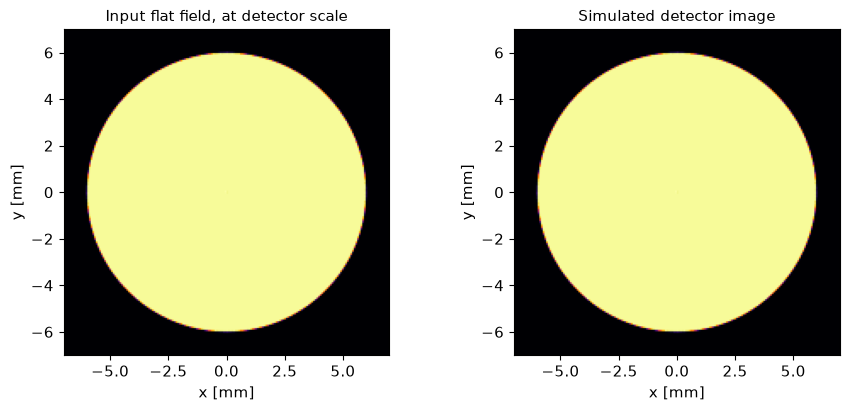

The central illuminated region varies by **0.019%**. The input and detector images agree after accounting for magnification.

In [4]:
image_width = SHAPE[1] * image_pitch
image_grid = grid(image_width)
object_grid = SimpleNamespace(shape=SHAPE, coords=image_grid.coords @ jnp.asarray(np.linalg.inv(A).T))
flat = disk(beam_radius, z_sample)
flat_out = propagate(flat, column)
flat_reference = intensity(flat, object_grid)
flat_image = intensity(flat_out, image_grid) * magnification**2
interior = (np.linalg.norm(np.asarray(object_grid.coords), axis=1) < .8*beam_radius).reshape(SHAPE)
flat_cv = float(flat_image[interior].std()/flat_image[interior].mean())
results["flat_field"] = dict(active_beamlets=int(flat.x.size), interior_cv=flat_cv,
    propagation_relative_l2=relerr(flat_image, flat_reference))

assert flat_cv < .01
assert results["flat_field"]["propagation_relative_l2"] < 1e-4
fig, ax = plt.subplots(1,2,figsize=(9,4),constrained_layout=True)
panel(ax[0],flat_reference,image_width,"Input flat field, at detector scale")
panel(ax[1],flat_image,image_width,"Simulated detector image")
plt.show()

display(Markdown(f"The central illuminated region varies by **{100*flat_cv:.3f}%**. "
                 "The input and detector images agree after accounting for magnification."))

## 2. Crossover and defocus

Hold the matched source fixed and vary CL3. The detector shows the illuminated field contracting to a crossover and expanding beyond it.

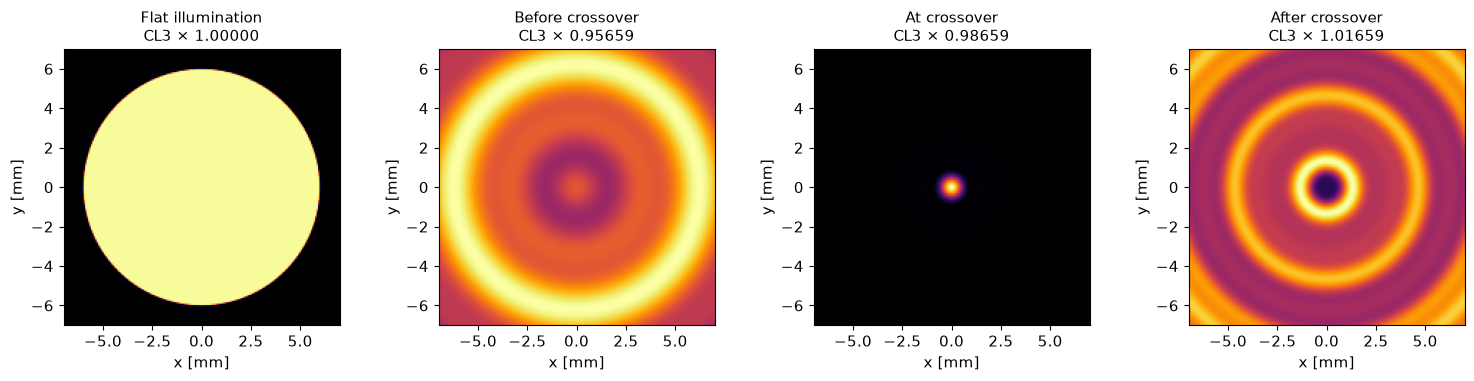

The fixed source contracts to a crossover at **CL3 × 0.98659** and expands beyond it. Each panel uses its own intensity scale; the narrow crossover is resolved separately in the numerical checks.

In [5]:
upstream = [c for c in model.with_settings(parallel=3.0).column if float(c.z)<z_sample]
# Zero-drive deflectors are retained in forward propagation; invert only powered lenses.
inverse = []
for c in reversed(upstream):
    if hasattr(c,"focal_length"):
        inverse += [Rotator(z=float(c.z), angle=-np.degrees(float(c.rotation_angle(voltage)))),
                    Lens(z=float(c.z), focal_length=-float(c.focal_length(voltage)))]
inverse += [Plane(z=float(model.config["beam"].get("z_source_m", 0.)))]
matched_source = propagate(flat,inverse)
cl3_z = float(model.components["CL3"].z)
def condenser(scale):
    return [replace(c,current=float(c.current)*scale) if float(c.z)==cl3_z else c for c in upstream]
def condenser_scalar(scale):
    transfer=np.eye(2); z=0.
    for c in condenser(scale):
        if hasattr(c,"focal_length"):
            f=float(c.focal_length(voltage))
            transfer=np.array([[1.,0.],[-1/f,1.]]) @ np.array([[1.,float(c.z)-z],[0.,1.]]) @ transfer
            z=float(c.z)
    return np.array([[1.,z_sample-z],[0.,1.]]) @ transfer
nominal_up=condenser_scalar(1.)
def crossover_gain(scale):
    return (condenser_scalar(scale) @ np.linalg.inv(nominal_up))[0,0]
scales = np.linspace(.2,2.0,61)
gains = np.array([crossover_gain(s) for s in scales])
changes = np.flatnonzero(gains[:-1]*gains[1:]<0)
assert len(changes), "Extend CL3 scan to bracket the crossover"
i = changes[np.argmin(abs(scales[changes]-1))]
crossover = brentq(crossover_gain,scales[i],scales[i+1],xtol=1e-12)
settings = [1.,crossover-.03,crossover,crossover+.03]
fig, axs = plt.subplots(1,4,figsize=(15,3.7),constrained_layout=True)
crossover_records=[]
for ax,s,label in zip(axs,settings,["Flat illumination", "Before crossover", "At crossover", "After crossover"]):
    b = propagate(matched_source,condenser(s)+[Plane(z=z_sample)]+column)
    im = intensity(b,image_grid)*magnification**2
    # Each panel explicitly labels its scale: crossover peak is much brighter.
    panel(ax,im,image_width,f"{label}\nCL3 × {s:.5f}")
    xx = np.asarray(image_grid.coords).reshape(*SHAPE,2)
    rms = np.sqrt((im*np.sum(xx**2,axis=-1)).sum()/im.sum())
    crossover_records.append(dict(current_scale=s, geometric_gain=crossover_gain(s),
                                  detector_rms_m=float(rms), sampled_peak=float(im.max())))
    if s==1.: results["condenser_round_trip_error"] = relerr(im,flat_image)
plt.show()
results["crossover"] = crossover_records

assert results["condenser_round_trip_error"] < 1e-3

display(Markdown(f"The fixed source contracts to a crossover at **CL3 × {crossover:.5f}** "
                 "and expands beyond it. Each panel uses its own intensity scale; "
                 "the narrow crossover is resolved separately in the numerical checks."))

Place an amplitude-and-phase specimen in the flat illumination, then vary objective current while keeping the detector fixed. Compare the focused image with equivalent defocus of −100 and +100 µm; fringes and changing contrast are the expected response.

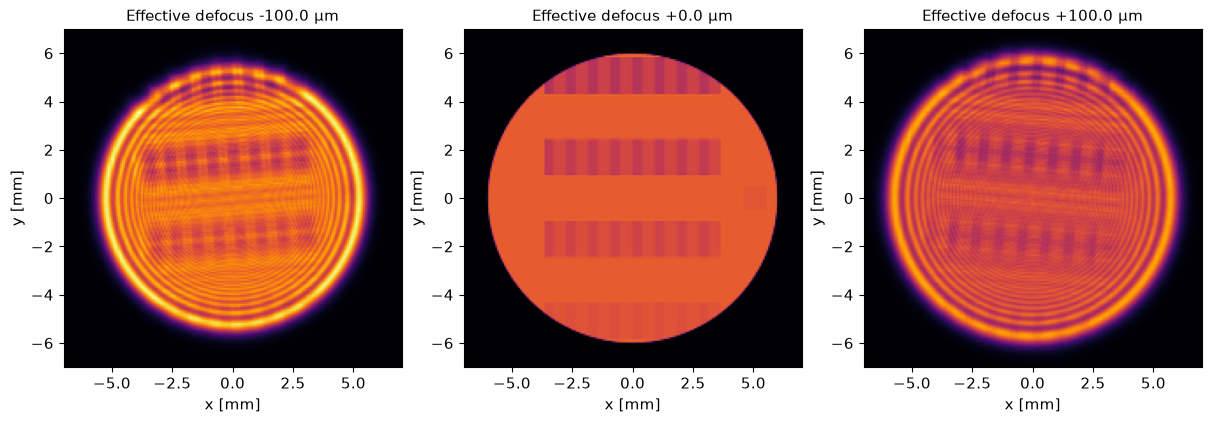

Changing objective current produces Fresnel fringes and changes specimen contrast. The detector position is fixed; the labels give equivalent specimen-plane defocus.

In [6]:
sample, specimen, _ = make_magical_sample(voltage,z=z_sample)
exit_wave = propagate(flat,[sample])
def defocus_column(delta):
    return [replace(lenses[0],current=float(lenses[0].current)*(1+delta))]+lenses[1:]+[Plane(z=z_image)]
# Differentiate the native column; no duplicate focal-length transfer model.
defocus_matrix = jax.jit(lambda delta: column_matrix(
    defocus_column(delta), source_z=z_sample, voltage=voltage))
def equivalent_defocus(delta):
    m = np.asarray(defocus_matrix(delta))
    return float(np.trace(np.linalg.solve(m[:2,:2], m[:2,2:4])) / 2)
# Target appreciable Fresnel contrast at the 10–23 nm specimen features.
target_defocus = [-100e-6,0.,100e-6]
defocused=[]; defocus_records=[]
for target in target_defocus:
    fit_d=least_squares(lambda x:[(equivalent_defocus(x[0])-target)/1e-4],[0.],
                        xtol=1e-12,ftol=1e-12,gtol=1e-12)
    delta=float(fit_d.x[0]); actual=equivalent_defocus(delta)
    assert abs(actual-target)<1e-8
    measured=matrix_for(defocus_column(delta),z_sample)
    np.testing.assert_allclose(np.trace(np.linalg.solve(measured[:2,:2],measured[:2,2:4]))/2,actual,atol=1e-10)
    im=intensity(propagate(exit_wave,defocus_column(delta)),image_grid)*magnification**2
    defocused.append(im)
    defocus_records.append(dict(objective_fractional_current_change=delta,effective_defocus_m=actual))
fig,axs=plt.subplots(1,3,figsize=(12,4),constrained_layout=True)
for ax,im,d in zip(axs,defocused,defocus_records):
    panel(ax,im,image_width,f"Effective defocus {d['effective_defocus_m']*1e6:+.1f} µm",vmax=max(i.max() for i in defocused))
plt.show()
results["defocus"] = defocus_records
results["defocus_image_changes"]=[relerr(i,defocused[1]) for i in defocused]
display(Markdown("Changing objective current produces Fresnel fringes and changes specimen contrast. "
                 "The detector position is fixed; the labels give equivalent specimen-plane defocus."))
assert min(results["defocus_image_changes"][::2])>.05

## 3. Objective aberrations

A 10 mrad pupil tests $C_s=0.5$–1 mm and 20 nm twofold astigmatism. The spherical coefficients represent an uncorrected objective ([JEOL](https://www.jeol.com/words/emterms/20121023.040959.php)); the astigmatism amplitude is a chosen test value.

The top row shows the ideal focus and two spherical-aberration strengths. The bottom row shows defocus compensation and two astigmatism orientations. Each panel is scaled to its corresponding Fourier reference, so compare the intensity distributions rather than brightness between panels.

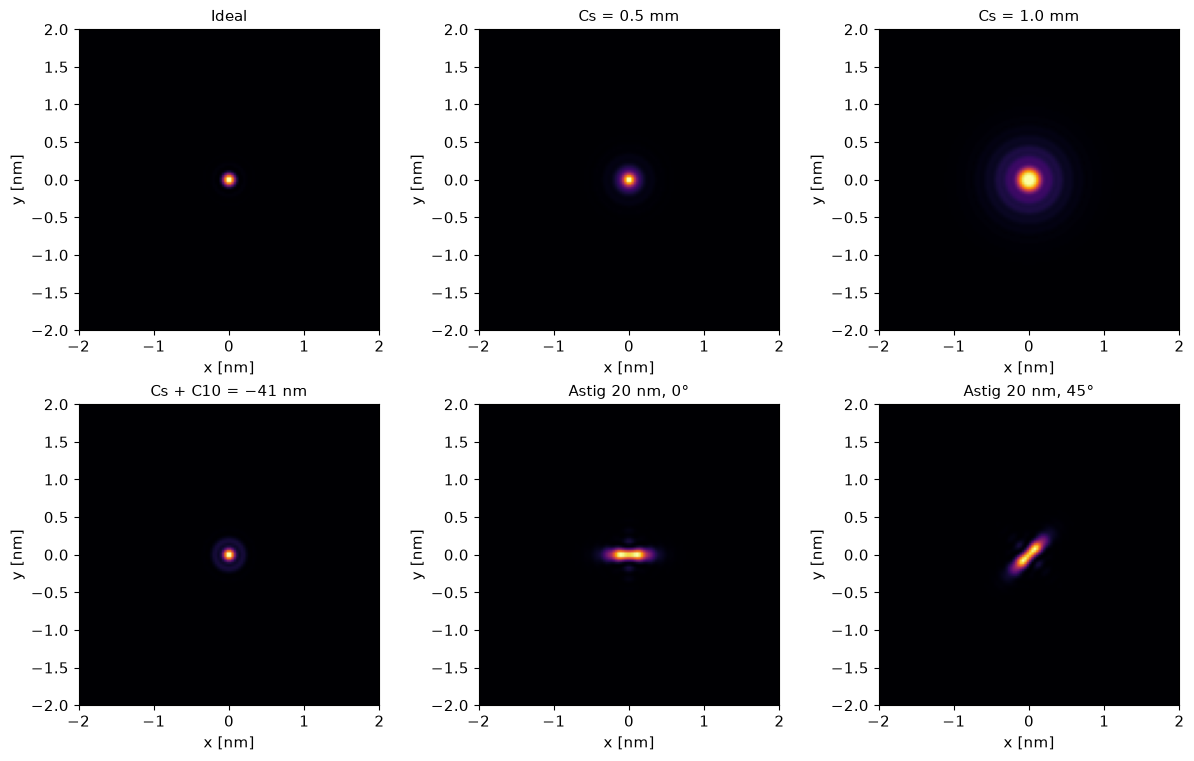

Spherical aberration redistributes the focal intensity, while astigmatism elongates it. Rotating the astigmatism coefficient by 45° rotates the measured image by **45.00°**. The largest intensity error against the independent Fourier calculation is **0.754%**.

In [7]:
f_obj=float(lenses[0].focal_length(voltage)); z_obj=float(lenses[0].z)
alpha_max=.010
wavelength=float(energy2wavelength(voltage)); k=2*np.pi/wavelength
pupil_radius=f_obj*alpha_max
pupil=disk(pupil_radius,z_obj)
probe_width=4e-9; probe_grid=grid(probe_width,(128,128))
case_coeffs={
    "Ideal":KrivanekCoeffs(),
    "Cs = 0.5 mm":KrivanekCoeffs(C30=.5e-3),
    "Cs = 1.0 mm":KrivanekCoeffs(C30=1e-3),
    "Cs + C10 = −41 nm":KrivanekCoeffs(C30=.5e-3,C10=-41e-9),
    "Astig 20 nm, 0°":KrivanekCoeffs(C12=20e-9,C10=20e-9),
    "Astig 20 nm, 45°":KrivanekCoeffs(C12=20e-9,C10=20e-9,phi12=np.pi/4),
}
def probe_image(coeffs,beam=pupil):
    objective=KrivanekLens(z=z_obj,focal_length=f_obj,coeffs=coeffs)
    b=propagate(beam,[objective,Plane(z=z_obj+f_obj)])
    return intensity(b,probe_grid)
# Independent Cartesian polynomial and FFT: no TemGym aberration evaluator.
fft_n=2048; pupil_step=pupil_radius/256
axis=(np.arange(fft_n)-fft_n//2)*pupil_step
px,py=np.meshgrid(axis,axis); ax,ay=px/f_obj,py/f_obj
rho2=ax*ax+ay*ay
fft_dx=wavelength*f_obj/(fft_n*pupil_step)
coords=np.asarray(probe_grid.coords)
fft_coords=np.array([coords[:,1]/fft_dx+fft_n//2,coords[:,0]/fft_dx+fft_n//2])
def fft_reference(c):
    astig=(ax*ax-ay*ay)*np.cos(2*c.phi12)+2*ax*ay*np.sin(2*c.phi12)
    W=.5*c.C10*rho2+.5*c.C12*astig+.25*c.C30*rho2**2
    wave=(rho2<=alpha_max**2)*np.exp(-1j*k*W)
    field=np.fft.fftshift(np.fft.fft2(np.fft.ifftshift(wave))) * pupil_step**2/(wavelength*f_obj)
    image=abs(field)**2
    return map_coordinates(image,fft_coords,order=3).reshape(probe_grid.shape)
probe_images={}; probe_references={}; probe_errors={}
fig,axs=plt.subplots(2,3,figsize=(12,7.5),constrained_layout=True)
for col,(label,c) in enumerate(case_coeffs.items()):
    im=probe_image(c); ref=fft_reference(c)
    probe_images[label]=im
    probe_references[label]=ref
    # Absolute normalization, no fitted gain; finite pupil smoothing is a residual.
    probe_errors[label]=relerr(im,ref)
    panel(axs.ravel()[col],im,probe_width,label,unit="nm",vmax=ref.max())
plt.show()
results["objective_fft_relative_l2"]=probe_errors
# Orientation is measured from image intensity, independently of coefficient labels.
def probe_shape(im):
    xy=np.asarray(probe_grid.coords); w=im.ravel()/im.sum()
    mean=(w[:,None]*xy).sum(axis=0); xy=xy-mean
    covariance=(xy.T*w)@xy
    eig,vec=np.linalg.eigh(covariance)
    return float(eig[-1]/eig[0]),float(np.arctan2(vec[1,-1],vec[0,-1]))
a0,p0=probe_shape(probe_images["Astig 20 nm, 0°"])
a45,p45=probe_shape(probe_images["Astig 20 nm, 45°"])
rotation_change=(p45-p0+np.pi/2)%np.pi-np.pi/2
results["astigmatism_image_shape"]=dict(axis_ratios=[a0,a45],rotation_change_deg=float(np.degrees(rotation_change)))
assert min(a0,a45)>1.2
assert abs(abs(np.degrees(rotation_change))-45)<3
assert max(probe_errors.values())<.06
assert relerr(probe_images["Cs = 0.5 mm"],probe_images["Ideal"])>.1

display(Markdown(f"Spherical aberration redistributes the focal intensity, while astigmatism elongates it. "
                 f"Rotating the astigmatism coefficient by 45° rotates the measured image by "
                 f"**{abs(np.degrees(rotation_change)):.2f}°**. The largest intensity error against "
                 f"the independent Fourier calculation is **{100*max(probe_errors.values()):.3f}%**."))

## 4. Projector distortion

Replace PL1 with `DistortedLens`, preserving its focal length and rotation. Its reference object distance is calculated from the nominal detector plane and lens focal length; individual object coordinates are inferred from each Gaussian's position and slope.

The coefficients produce approximately 6% edge displacement. The top row compares radial distortion, and the bottom row compares spiral distortion, each against the undistorted grid.

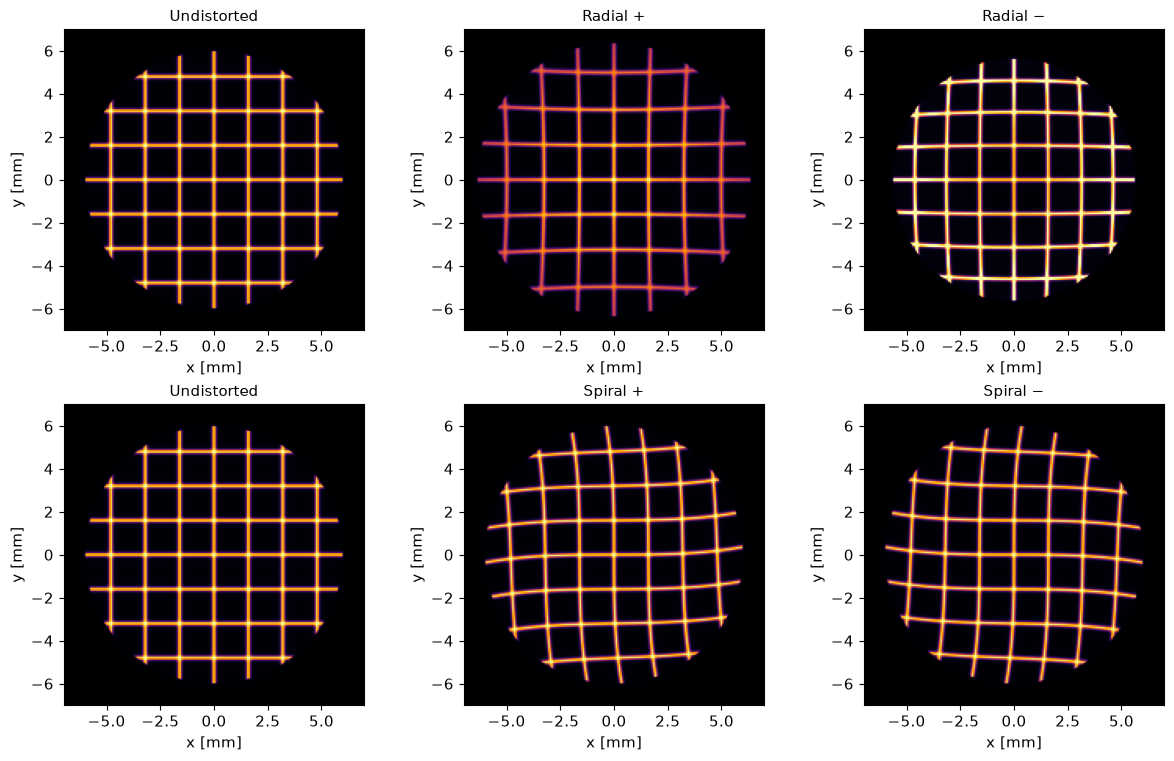

Radial distortion changes grid spacing with radius; spiral distortion changes its orientation with radius. Reversing each coefficient reverses the deformation. All six panels share an intensity scale.

In [8]:
pl=lenses[-1]; z_pl=float(pl.z); f_pl=float(pl.focal_length(voltage))
z2=z_image-z_pl; z1=1/(1/f_pl-1/z2); Mpl=-z2/z1
angle=float(pl.rotation_angle(voltage))
Rpl=np.array([[np.cos(angle),-np.sin(angle)],[np.sin(angle),np.cos(angle)]])
pl_rotation=Rotator(z=z_pl,angle=np.degrees(angle))
pitch=40e-9; line_sigma=2e-9

def grid_source(count=N_BEAMLETS):
    beam=disk(beam_radius,z_sample,count=count)
    x,y=np.asarray(beam.r_xy).T
    dx=(x+pitch/2)%pitch-pitch/2; dy=(y+pitch/2)%pitch-pitch/2
    transmission=.12+.88*(1-(1-np.exp(-dx**2/(2*line_sigma**2)))*(1-np.exp(-dy**2/(2*line_sigma**2))))
    return beam.derive(amplitude=beam.amplitude*jnp.asarray(transmission))

source_grid=grid_source()
arriving=propagate(source_grid,lenses[:-1]+[Plane(z=z_pl)])
ideal=propagate(arriving,[Lens(z=z_pl,focal_length=f_pl),Plane(z=z_image)])
obj=np.asarray(ideal.r_xy)/Mpl
radius=np.linalg.norm(obj,axis=1)
edge=radius>np.quantile(radius,.9)
cubic=np.sum(obj**2,axis=1)[:,None]*obj
coefficient=.06*np.percentile(np.linalg.norm(np.asarray(ideal.r_xy)[edge],axis=1),90)/(z2*np.percentile(np.linalg.norm(cubic[edge],axis=1),90))

def distorted(beam,E,e):
    lens=DistortedLens(z=z_pl,focal_length=f_pl,object_plane_dist=z1,
                      IsoDist=E,AnisoDist=e)
    return propagate(beam,[lens,pl_rotation,Plane(z=z_image)])

cases=[("Zero",0.,0.),("Radial +",coefficient,0.),("Radial −",-coefficient,0.),
       ("Spiral +",0.,coefficient),("Spiral −",0.,-coefficient)]
images={}; fields={}; centre_errors={}
for name,E,e in cases:
    out=distorted(arriving,E,e)
    field=np.asarray(evaluate_gaussians(out,image_grid,method=METHOD,tile_beams=32))
    assert np.isfinite(field).all()
    fields[name]=field
    images[name]=abs(field)**2*magnification**2
    gradient=np.sum(obj**2,axis=1)[:,None]*(E*obj+e*np.c_[-obj[:,1],obj[:,0]])
    predicted=(np.asarray(ideal.r_xy)-z2*gradient)@Rpl.T
    centre_errors[name]=float(np.max(np.linalg.norm(np.asarray(out.r_xy)-predicted,axis=1)))
    assert centre_errors[name]<1e-9
fig,axs=plt.subplots(2,3,figsize=(12,7.5),constrained_layout=True)
for ax,(name,_,_) in zip(axs.ravel(),[cases[0],cases[1],cases[2],cases[0],cases[3],cases[4]]):
    panel(ax,images[name],image_width,"Undistorted" if name=="Zero" else name,
          vmax=images["Zero"].max())
plt.show()
results["PL1_coefficients_per_m3"]=float(coefficient)
results["PL1_centre_errors_m"]=centre_errors
display(Markdown("Radial distortion changes grid spacing with radius; spiral distortion changes "
                 "its orientation with radius. Reversing each coefficient reverses the deformation. "
                 "All six panels share an intensity scale."))

## Numerical checks

These calculations check the images above against independent references and finer Gaussian sampling. Relative errors are $\|u-u_{\mathrm{ref}}\|_2/\|u_{\mathrm{ref}}\|_2$; “complex-field error” includes phase, whereas “intensity error” compares $|u|^2$.

### Crossover profile

Resolve the narrow crossover on a finer physical field of view and compare its intensity with the Airy prediction for a circular field.

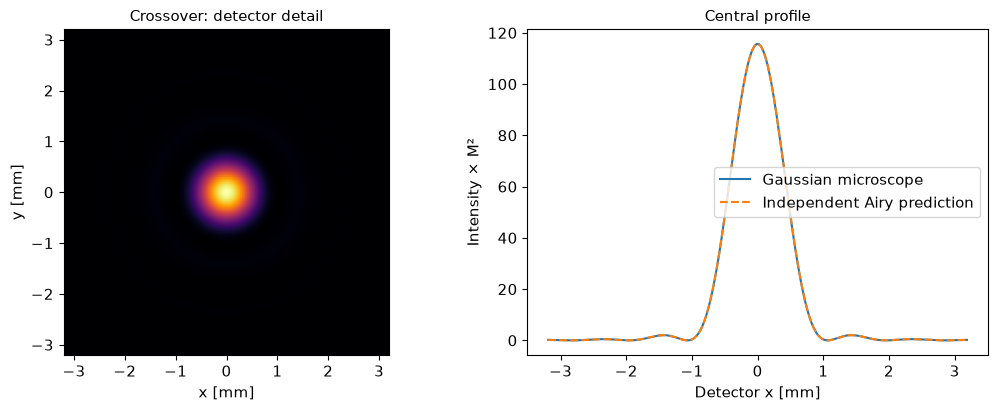

The crossover intensity differs from the independent Airy calculation by **0.167%**.

In [9]:
# The fixed overview grid can miss a narrow crossover; use a separate physical zoom.
source_z = float(model.config["beam"].get("z_source_m", 0.))
nominal_matrix = matrix_for(condenser(1.) + [Plane(z=z_sample)], source_z)
crossover_matrix = matrix_for(condenser(crossover) + [Plane(z=z_sample)], source_z)
cross_matrix = matrix @ crossover_matrix @ np.linalg.inv(nominal_matrix)
B_cross = np.linalg.svd(cross_matrix[:2, 2:4], compute_uv=False).mean()
first_zero=.609835*float(energy2wavelength(voltage))*abs(B_cross)/beam_radius
zoom_width=6*first_zero
zoom = grid(zoom_width,(192,192))
focus_beam = propagate(matched_source,condenser(crossover)+[Plane(z=z_sample)]+column)
zoom_image = intensity(focus_beam,zoom)*magnification**2
# Independent Fourier-transform prediction at A=0: the disk becomes an Airy field.
from scipy.special import j1
radial=np.linalg.norm(np.asarray(zoom.coords),axis=1).reshape(zoom.shape)
u=2*np.pi*beam_radius*radial/(float(energy2wavelength(voltage))*abs(B_cross))
airy=np.ones_like(u); np.divide(2*j1(u),u,out=airy,where=u!=0)
reference=(np.pi*beam_radius**2/(float(energy2wavelength(voltage))*abs(B_cross))*airy)**2*magnification**2
results["crossover_airy_relative_l2"]=relerr(zoom_image,reference)

assert results["crossover_airy_relative_l2"]<.03
assert crossover_records[2]["detector_rms_m"]<crossover_records[0]["detector_rms_m"]*.5
fig,axs=plt.subplots(1,2,figsize=(10,4),constrained_layout=True)
panel(axs[0],zoom_image,zoom_width,"Crossover: detector detail")
ax=axs[1]
mid=zoom.shape[0]//2
axis=np.asarray(zoom.coords).reshape(*zoom.shape,2)[mid,:,0]*1e3
ax.plot(axis,zoom_image[mid],label="Gaussian microscope")
ax.plot(axis,reference[mid],"--",label="Independent Airy prediction")
ax.set(xlabel="Detector x [mm]",ylabel="Intensity × M²",title="Central profile")
ax.legend(); plt.show()

display(Markdown(f"The crossover intensity differs from the independent Airy calculation by "
                 f"**{100*results['crossover_airy_relative_l2']:.3f}%**."))

### Objective accuracy and the remaining omission

Compare the objective images with a separate Cartesian aberration polynomial and Fourier propagation. Test the exact-axis astigmatism Hessian, increase the Gaussian count, and compare the spatial renderer with a dense coherent sum. `C10` uses the [documented wave-aberration sign convention](https://abtem.github.io/doc/user_guide/appendix/conventions.html).

In [10]:
rows = ["| Objective case | Intensity error against FFT |", "|---|---:|"]
for name, error in probe_errors.items():
    rows.append(f"| {name} | {100*error:.3f}% |")
display(Markdown("\n".join(rows)))

| Objective case | Intensity error against FFT |
|---|---:|
| Ideal | 0.260% |
| Cs = 0.5 mm | 0.684% |
| Cs = 1.0 mm | 0.754% |
| Cs + C10 = −41 nm | 0.316% |
| Astig 20 nm, 0° | 0.321% |
| Astig 20 nm, 45° | 0.293% |

In [11]:
axis_lens=KrivanekLens(z=z_obj,focal_length=f_obj,coeffs=KrivanekCoeffs(C12=20e-9))
axis_h=np.asarray(jax.hessian(axis_lens.phase_shift)(jnp.zeros(2)))+np.eye(2)/f_obj
axis_expected=np.diag([-20e-9,20e-9])/f_obj**2
axis_ok=bool(np.allclose(axis_h,axis_expected,rtol=1e-7,atol=1e-10))
results["exact_axis_astigmatism"]=dict(passed=axis_ok,actual=axis_h.tolist(),expected=axis_expected.tolist())
refined_pupil=disk(pupil_radius,z_obj,count=REFINED_BEAMLETS)
refined_probe=probe_image(case_coeffs["Cs = 1.0 mm"],refined_pupil)
refinement_error=relerr(probe_images["Cs = 1.0 mm"],refined_probe)
results["pupil_refinement_relative_l2"]=refinement_error
assert refinement_error<.03
check_grid=SimpleNamespace(shape=(1,64),coords=probe_grid.coords[::256][:64])
check_out=propagate(pupil,[KrivanekLens(z=z_obj,focal_length=f_obj,coeffs=case_coeffs["Cs = 0.5 mm"]),Plane(z=z_obj+f_obj)])
fast=intensity(check_out,check_grid)
dense=intensity(check_out,check_grid,method="scan")
results["renderer_relative_l2"]=relerr(fast,dense)
assert results["renderer_relative_l2"]<1e-5

axis_status = "reproduces the expected quadratic term" if axis_ok else "omits the quadratic term"
display(Markdown(f"**Exact-axis astigmatism:** the current branch {axis_status}. "
                 f"Increasing the pupil count to {REFINED_BEAMLETS:,} changes the Cs image by "
                 f"**{100*refinement_error:.3f}%**; the spatial and dense renderers agree to "
                 f"**{results['renderer_relative_l2']:.2e}** relative error."))

**Exact-axis astigmatism:** the current branch omits the quadratic term. Increasing the pupil count to 330,000 changes the Cs image by **0.142%**; the spatial and dense renderers agree to **2.49e-14** relative error.

In [12]:
integrated_images=[]
for label,c in [("Zero aberrations",KrivanekCoeffs()),("Cs = 1 mm",KrivanekCoeffs(C30=1e-3)),
                ("Astig 20 nm",KrivanekCoeffs(C12=20e-9,phi12=np.pi/4))]:
    objective=KrivanekLens(z=z_obj,focal_length=f_obj,coeffs=c)
    rotation=Rotator(z=z_obj,angle=np.degrees(float(lenses[0].rotation_angle(voltage))))
    b=propagate(exit_wave,[objective,rotation]+lenses[1:]+[Plane(z=z_image)])
    integrated_images.append((label,intensity(b,image_grid)*magnification**2))
results["objective_full_column_image_changes"]={label:relerr(im,defocused[1]) for label,im in integrated_images}
display(Markdown("The zero-aberration objective reproduces the original full-column image. "
                 "The overview specimen samples smaller angles than the 10 mrad pupil, "
                 "so its response to these objective coefficients is much weaker."))
assert results["objective_full_column_image_changes"]["Zero aberrations"]<1e-5

The zero-aberration objective reproduces the original full-column image. The overview specimen samples smaller angles than the 10 mrad pupil, so its response to these objective coefficients is much weaker.

### Distortion accuracy

Compare the Gaussian calculation with the analytic unbounded-pupil distortion field, then increase the source count from 220,000 to 330,000. The [derivation](seidel_gaussian_action.md) specifies the phase and amplitude conventions. Field-dependent pupil apodization is unspecified, so this phase-aberration model does not impose flux conservation for arbitrary coefficients.

In [13]:
k=float(arriving.k[0])
Y=np.asarray(image_grid.coords)@Rpl
radius_out2=np.sum(Y**2,axis=1)
reference_errors={}
for name,E,e in [cases[1],cases[3]]:
    cr=z2*E/Mpl**3; ct=z2*e/Mpl**3
    radius2=radius_out2.copy()
    for _ in range(20):
        derivative=1-4*cr*radius2+3*(cr*cr+ct*ct)*radius2**2
        radius2-=(radius2*(1-2*cr*radius2+(cr*cr+ct*ct)*radius2**2)-radius_out2)/derivative
    a=1-cr*radius2; b=-ct*radius2
    inverse_xy=np.c_[(a*Y[:,0]+b*Y[:,1])/(a*a+b*b),(-b*Y[:,0]+a*Y[:,1])/(a*a+b*b)]
    determinant=1-4*cr*radius2+3*(cr*cr+ct*ct)*radius2**2
    assert np.all(determinant>0)
    inverse_grid=SimpleNamespace(shape=SHAPE,coords=jnp.asarray(inverse_xy))
    base=np.asarray(evaluate_gaussians(ideal,inverse_grid,method=METHOD,tile_beams=32))
    reference=(base.ravel()/determinant*np.exp(1j*k*(radius_out2-radius2)/(2*z2))).reshape(SHAPE)
    reference_errors[name]=dict(field=relerr(fields[name],reference),intensity=relerr(abs(fields[name])**2,abs(reference)**2))
    assert reference_errors[name]["field"]<.02
    assert reference_errors[name]["intensity"]<.02
results["distortion_reference_errors"]=reference_errors

refined=propagate(grid_source(REFINED_BEAMLETS),lenses[:-1]+[Plane(z=z_pl)])
refinement={}
for name,E,e in [cases[0],cases[1],cases[3]]:
    im=intensity(distorted(refined,E,e),image_grid)*magnification**2
    refinement[name]=relerr(images[name],im)
    assert refinement[name]<.04
results["distortion_basis_refinement"]=refinement
rows = ["| Distortion | Complex-field error | Intensity error | Beam-count change |",
        "|---|---:|---:|---:|"]
for name, error in reference_errors.items():
    rows.append(f"| {name} | {100*error['field']:.3f}% | {100*error['intensity']:.3f}% | {100*refinement[name]:.2f}% |")
display(Markdown("\n".join(rows)))

| Distortion | Complex-field error | Intensity error | Beam-count change |
|---|---:|---:|---:|
| Radial + | 0.896% | 0.748% | 2.34% |
| Spiral + | 0.108% | 0.019% | 2.02% |

Directly integrate the full Seidel diffraction kernel for a small off-axis Gaussian. Narrowing the source tests the local quadratic approximation; no phase alignment or intensity normalization is fitted.

In [14]:
from temgym_core.components import DistortedLens
from temgym_core.gaussian import FreeSpacePropagator

probe_z1=.02; probe_f=.01
probe_errors_distortion={}
for name,E,e in [("Radial",3e12,0.),("Spiral",0.,3e12)]:
    errors=[]
    for width in [80e-9,40e-9,20e-9]:
        source=make_gaussian(x=.8e-6,y=.25e-6,dx=2e-5,dy=-1e-5,
                             waist_x=width,waist_y=width,z=0.,voltage=voltage)
        beam=FreeSpacePropagator(include_axial_path=False)(source,probe_z1)
        lens=DistortedLens(z=probe_z1,focal_length=probe_f,object_plane_dist=probe_z1,
                           IsoDist=E,AnisoDist=e)
        out=jax.jit(lambda b:lens(b))(beam)
        kp=float(source.k)
        sigma=1/np.sqrt(kp*np.imag(np.asarray(beam.Q_inv)[0,0]))
        a=np.linspace(-2.5*sigma,2.5*sigma,25)
        xx,yy=np.meshgrid(a+float(beam.x),a+float(beam.y))
        points=np.c_[xx.ravel(),yy.ravel()]
        grid=SimpleNamespace(shape=xx.shape,coords=jnp.asarray(points))
        actual=np.asarray(evaluate_gaussians(out,grid,method="scan")).ravel()
        u=np.linspace(-6*width,6*width,121)
        ux,uy=np.meshgrid(u,u); offsets=np.c_[ux.ravel(),uy.ravel()]
        objects=offsets+np.asarray(source.r_xy)
        incoming=offsets@np.asarray(source.d_xy)+.5*np.einsum("ni,ij,nj->n",offsets,np.asarray(source.Q_inv),offsets)
        reference=[]
        for pupil in np.array_split(points,16):
            dot=pupil@objects.T
            cross=pupil[:,1,None]*objects[None,:,0]-pupil[:,0,None]*objects[None,:,1]
            W=np.sum(objects**2,axis=1)[None,:]*(E*dot+e*cross)
            action=incoming[None,:]+np.sum((pupil[:,None,:]-objects[None,:,:])**2,axis=-1)/(2*probe_z1)
            action=action-np.sum(pupil**2,axis=1)[:,None]/(2*probe_f)-W
            reference.extend(np.exp(1j*kp*action).sum(axis=1)*(u[1]-u[0])**2*kp/(2j*np.pi*probe_z1))
        errors.append(relerr(actual,np.asarray(reference)))
    assert errors[2]<errors[1]<errors[0]
    assert errors[-1]<.003
    probe_errors_distortion[name]=errors
results["distortion_direct_quadrature"]=probe_errors_distortion
rows = ["| Distortion | 80 nm source width | 40 nm | 20 nm |", "|---|---:|---:|---:|"]
for name, errors in probe_errors_distortion.items():
    rows.append("| " + name + " | " + " | ".join(f"{100*e:.3f}%" for e in errors) + " |")
display(Markdown("\n".join(rows)))

| Distortion | 80 nm source width | 40 nm | 20 nm |
|---|---:|---:|---:|
| Radial | 0.990% | 0.419% | 0.210% |
| Spiral | 0.495% | 0.246% | 0.123% |

### Fitted finite projector

Repeat the flat-field check with the separately fitted finite-solenoid projector. This is a control for propagation through that model; the primary image sections use the TOML microscope.

In [15]:
from temgym_core.calibration.projector_model import projector_components, matrix5, decode_geometry
saved = json.loads((repo / "examples/microscope_models/calibration_results/full_gaussian_recovery.json").read_text())
p_finite = np.asarray(saved["full_fit"]["projector_parameters"])
views = json.loads((repo / "src/temgym_core/calibration/presets/condenser_projector_views.json").read_text())
start = np.asarray(views["views"][0]["controls"], dtype=float)
finite_matrix = jax.jit(lambda u: matrix5(p_finite, u))
def finite_residual(v):
    u = start.copy(); u[1:] = v
    m = np.asarray(finite_matrix(u))
    # Signed scalar A/B in the frame defined by A.
    a = np.linalg.norm(m[:2,0]); rotation = m[:2,:2]/a
    return [a/magnification-1, (rotation.T @ m[:2,2:4])[0,0]/(magnification*1e-3)]
f_fit = least_squares(finite_residual, start[1:], bounds=(.05,4.5),
                      xtol=1e-12,ftol=1e-12,gtol=1e-12,max_nfev=500)
u_finite = np.r_[start[0],f_fit.x]
np.testing.assert_allclose(finite_residual(f_fit.x),0,atol=1e-7)
finite_column = projector_components(p_finite,u_finite)
m_finite = np.asarray(finite_matrix(u_finite)); a_finite = m_finite[:2,:2]
finite_grid = SimpleNamespace(shape=SHAPE,coords=object_grid.coords @ jnp.asarray(a_finite.T))
finite_input = flat.derive(z=jnp.zeros_like(flat.z))
finite_image = intensity(propagate(finite_input,finite_column),finite_grid)*abs(np.linalg.det(a_finite))
results["finite_projector"] = dict(relative_l2=relerr(finite_image,flat_reference), controls=u_finite.tolist())
display(Markdown(f"The separately fitted finite-solenoid projector reproduces the flat-field "
                 f"reference with relative intensity error **{results['finite_projector']['relative_l2']:.2e}**."))
assert results["finite_projector"]["relative_l2"] < 1e-4

The separately fitted finite-solenoid projector reproduces the flat-field reference with relative intensity error **3.74e-11**.

## 5. Source → condenser aperture → specimen

This section runs on its own. It tests the **initial condenser guess**, not a fitted microscope. A source made of overlapping Gaussian beamlets goes through CL1, CL3, a sigmoid aperture, the mini lens and the objective prefield. We sum the complex fields at the specimen on a 256×256 grid.

Start with the preset's **10 nm RMS effective source size**, a **10 µm aperture diameter**, and a **20 nm sigmoid edge width** (the logistic scale, not the full transition width). These are simulation inputs, not measured microscope specifications. This first check uses **one coherent source mode**: its angular RMS is set by diffraction, about **0.020 mrad per axis at 200 kV**. It does not yet add the preset's extra incoherent angular spread. Many coherent beamlets represent that one mode; they are not independent electrons.

In [1]:
import os
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")
from pathlib import Path
from dataclasses import replace
from types import SimpleNamespace
from time import perf_counter
import json
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from temgym_core.components import solenoid_column, Plane, Detector, SigmoidAperture
from temgym_core.source import gaussian_waist, decompose_gaussian
from temgym_core.gaussian import FreeSpacePropagator
from temgym_core.run import run_to_end, column_matrix
from temgym_core.evaluate import evaluate_gaussians, gpu_kernel_available

repo = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/temgym_core").is_dir())
initial_guess = json.loads((repo / "src/temgym_core/calibration/presets/microscope_condenser_starting_guess.json").read_text())["model"]
illumination_voltage = 200_000.
source_rms_m = initial_guess["source_rms_nm"] * 1e-9
aperture_diameter_m = 10e-6
aperture_edge_m = 20e-9
beamlets_across = 768  # 589,824 coherent beamlets

# Keep the initial lens geometry and strengths; centre the source and aperture.
gaps = np.asarray(initial_guess["gaps_mm"]) * 1e-3
lengths = np.asarray(initial_guess["lens_lengths_mm"]) * 1e-3
strengths = np.asarray(initial_guess["strength_magnitudes"]) * [1, 1, 1, -1]
illumination_source_z = -sum(gaps) - sum(lengths)
condenser = tuple(replace(c, include_axial_path=False) if hasattr(c, "q") else c
    for c in solenoid_column(gaps, lengths, strengths, source_z=illumination_source_z))
aperture_z = condenser[1].z + condenser[1].length + initial_guess["aperture_gap_fraction"] * gaps[2]
illumination_upstream = (*condenser[:2], Plane(z=aperture_z))
illumination_downstream = condenser[2:]
illumination_aperture = SigmoidAperture(z=aperture_z, radius=aperture_diameter_m/2, edge_width=aperture_edge_m)
illumination_source = gaussian_waist(z=illumination_source_z, voltage=illumination_voltage, rms_size=source_rms_m)
illumination_grid = Detector(z=condenser[-1].z, shape=(256, 256), pixel_size=(8e-6/256,)*2)
illumination_propagator = FreeSpacePropagator(include_axial_path=False)
assert gpu_kernel_available(), "This large benchmark requires the working GPU Gaussian kernel."
print(jax.devices()[0].device_kind)

NVIDIA GH200 144G HBM3e


**The source stays fixed when we add beamlets.** `decompose_gaussian` chooses overlapping beamlets narrow at the aperture, then maps them back to the source plane using the native column. Gaussian convolution sets their weights. This is a numerical representation of the specified Gaussian source, not a prescribed specimen image. Source tests also check its field before the first lens and after changing a lens setting.

Supply the source, the column ending just before the aperture, and the sampling count. Receive a source-plane `GaussianBeam` bundle. The aperture itself is applied only during the subsequent forward propagation.

In [2]:
# Input: one physical source and the desired aperture-plane sampling.
# Output: a source-plane bundle of 589,824 interfering Gaussian beamlets.
illumination_beamlets = decompose_gaussian(
    illumination_source, num_across=beamlets_across, through=illumination_upstream,
)

# Input: that source bundle. Output: the field-carrying bundle at the specimen.
illumination_column = (*condenser[:2], illumination_aperture, *illumination_downstream)
propagate_illumination = jax.jit(lambda beam: run_to_end(
    beam, illumination_column, propagator=illumination_propagator,
))
illumination_at_sample = propagate_illumination(illumination_beamlets)

# Input: the specimen-plane bundle and observation grid. Output: complex field.
illumination_field = evaluate_gaussians(
    illumination_at_sample, illumination_grid, method="spatial", tile_beams=32,
)
illumination_intensity = np.abs(np.asarray(illumination_field))**2

**Check the physics independently.** For this centred round column, a radial Fresnel integral gives a reference without any Gaussian beamlets. It uses the native aperture-to-specimen matrix and the exact incident Gaussian, multiplied by the same sigmoid transmission. Doubling its quadrature resolution checks the reference itself. This calculation is only a validation reference; the forward images above use Gaussian summation.

In [3]:
from scipy.integrate import simpson
from scipy.special import j0, expit

incident_at_aperture = run_to_end(illumination_source, illumination_upstream, propagator=illumination_propagator)
aperture_to_sample = np.asarray(column_matrix(illumination_downstream, source_z=aperture_z, voltage=illumination_voltage))[:4, :4]
# Each 2x2 block is a scalar times the same Larmor rotation.
angle = sum(float(c.q) for c in illumination_downstream if hasattr(c, "q"))
rotation = np.array([[np.cos(angle), np.sin(angle)], [-np.sin(angle), np.cos(angle)]])
a, b, c, d = [np.trace(rotation.T @ aperture_to_sample[i:i+2, j:j+2])/2
              for i, j in [(0, 0), (0, 2), (2, 0), (2, 2)]]

def illumination_reference(radii, *, radial_samples=32769):
    """Radial diffraction quadrature: supplied radii in metres -> complex field."""
    rho = np.linspace(0, illumination_aperture.radius + 24*aperture_edge_m, radial_samples)
    k = float(incident_at_aperture.k)
    incident = complex(incident_at_aperture.amplitude) * np.exp(1j*k*float(incident_at_aperture.pathlength))
    incident = incident * np.exp(.5j*k*complex(incident_at_aperture.Q_inv[0, 0])*rho**2)
    integrand = incident * expit((illumination_aperture.radius-rho)/aperture_edge_m)
    integrand = integrand * np.exp(.5j*k*a/b*rho**2) * rho
    values = []
    for rr in np.array_split(np.asarray(radii), max(1, len(radii)//64)):
        integral = simpson(j0(k/b*rr[:, None]*rho) * integrand, x=rho, axis=1)
        values.extend(k/(1j*b) * np.exp(.5j*k*d/b*rr**2) * integral)
    return np.asarray(values)

illumination_radii = np.linspace(0, 4e-6, 1025)
illumination_line_grid = SimpleNamespace(shape=illumination_radii.shape,
    coords=jnp.asarray(np.column_stack((illumination_radii, np.zeros_like(illumination_radii)))))
reference_field = illumination_reference(illumination_radii)
reference_refined = illumination_reference(illumination_radii, radial_samples=65537)
reference_error = np.linalg.norm(reference_field-reference_refined) / np.linalg.norm(reference_refined)
assert reference_error < 1e-6
reference_intensity = abs(reference_refined)**2
print(f"Reference quadrature refinement: {reference_error:.2e} relative field error")

Reference quadrature refinement: 1.80e-09 relative field error


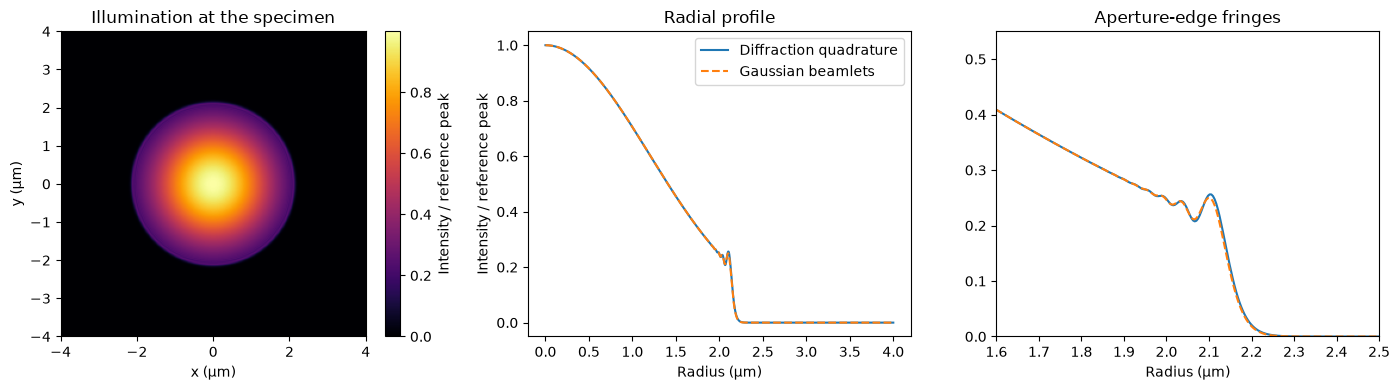

In [4]:
illumination_line = np.abs(np.asarray(evaluate_gaussians(
    illumination_at_sample, illumination_line_grid, method="spatial", tile_beams=32,
)))**2
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
peak = reference_intensity.max()
artist = axes[0].imshow(illumination_intensity/peak, origin="lower", extent=(-4, 4, -4, 4), cmap="inferno")
axes[0].set(title="Illumination at the specimen", xlabel="x (µm)", ylabel="y (µm)")
fig.colorbar(artist, ax=axes[0], label="Intensity / reference peak")
axes[1].plot(illumination_radii*1e6, reference_intensity/peak, label="Diffraction quadrature")
axes[1].plot(illumination_radii*1e6, illumination_line/peak, "--", label="Gaussian beamlets")
axes[1].set(xlabel="Radius (µm)", ylabel="Intensity / reference peak", title="Radial profile")
axes[1].legend()
axes[2].plot(illumination_radii*1e6, reference_intensity/peak)
axes[2].plot(illumination_radii*1e6, illumination_line/peak, "--")
axes[2].set(xlim=(1.6, 2.5), ylim=(0, .55), xlabel="Radius (µm)", title="Aperture-edge fringes")
fig.tight_layout()
plt.show()

**Measure speed and convergence separately.** The table reports source construction, the first propagation and render in this loop (including compilation where it was not already cached), and median warm timings from three repetitions. Each timer waits for GPU completion. Images are point samples of specimen illumination, not detector pixel integrals.

The intensity error is an area-weighted radial error, equivalent to a relative 2D intensity error for this round reference. The spatial/full comparison uses the full **complex Gaussian sum** along the same radial line. We also inspect the renderer's bins to distinguish actual spatial summation from its dense fallback. Narrower beamlets eventually spread more on the way to the specimen, so more beamlets need not be faster.

In [5]:
# This internal diagnostic is used only to report which renderer path ran.
from temgym_core.evaluate import _build_spatial_bins

def timed_illumination(call):
    start = perf_counter()
    value = call()
    jax.block_until_ready(value)
    return value, perf_counter()-start

def illumination_error(image_line):
    numerator = np.trapezoid((image_line-reference_intensity)**2 * illumination_radii, illumination_radii)
    denominator = np.trapezoid(reference_intensity**2 * illumination_radii, illumination_radii)
    return float(np.sqrt(numerator/denominator))

illumination_benchmarks = []
for num_across in (384, 512, 768, 1024):
    bundle, setup_s = timed_illumination(lambda: decompose_gaussian(
        illumination_source, num_across=num_across, through=illumination_upstream))
    at_sample, first_propagation_s = timed_illumination(lambda: propagate_illumination(bundle))
    propagation_s = np.median([timed_illumination(lambda: propagate_illumination(bundle))[1] for _ in range(3)])
    render = lambda: evaluate_gaussians(at_sample, illumination_grid, method="spatial", tile_beams=32)
    field, first_render_s = timed_illumination(render)
    render_s = np.median([timed_illumination(render)[1] for _ in range(3)])
    vector = at_sample.to_vector()
    bins = _build_spatial_bins(vector.r_xy, vector.Q_inv, vector.k, cutoff=1e-12, bins_per_axis=64)
    spatial_line = np.asarray(evaluate_gaussians(at_sample, illumination_line_grid, method="spatial", tile_beams=32))
    full_line = np.asarray(evaluate_gaussians(at_sample, illumination_line_grid, method="gpu_kernel_required", tile_beams=32))
    row = dict(beamlets=num_across**2, source_s=setup_s,
               first_propagation_s=first_propagation_s, first_render_s=first_render_s,
               propagation_ms=1000*float(propagation_s), render_ms=1000*float(render_s),
               dense_fallback=bool(bins.use_dense), intensity_error=illumination_error(abs(spatial_line)**2),
               spatial_field_error=float(np.linalg.norm(spatial_line-full_line)/np.linalg.norm(full_line)))
    illumination_benchmarks.append(row)

rows = ["| Beamlets | Source setup (s) | First propagation / render (s) | Warm propagation / render (ms) | Intensity error | Dense fallback? |",
        "|---:|---:|---:|---:|---:|:---:|"]
for row in illumination_benchmarks:
    rows.append(f"| {row['beamlets']:,} | {row['source_s']:.2f} | {row['first_propagation_s']:.2f} / {row['first_render_s']:.2f} | {row['propagation_ms']:.1f} / {row['render_ms']:.1f} | {100*row['intensity_error']:.3f}% | {row['dense_fallback']} |")
display(Markdown("\n".join(rows)))
print("Largest spatial/full field error:", max(row["spatial_field_error"] for row in illumination_benchmarks))
assert max(row["spatial_field_error"] for row in illumination_benchmarks) < 1e-9
assert illumination_benchmarks[-1]["intensity_error"] < illumination_benchmarks[0]["intensity_error"]
assert illumination_benchmarks[-1]["intensity_error"] < .01

| Beamlets | Source setup (s) | First propagation / render (s) | Warm propagation / render (ms) | Intensity error | Dense fallback? |
|---:|---:|---:|---:|---:|:---:|
| 147,456 | 1.62 | 1.82 / 0.79 | 3.1 / 19.6 | 1.677% | False |
| 262,144 | 1.67 | 1.82 / 0.88 | 5.3 / 30.4 | 1.154% | False |
| 589,824 | 0.14 | 0.01 / 0.08 | 13.5 / 81.6 | 0.505% | False |
| 1,048,576 | 2.06 | 3.73 / 1.07 | 23.6 / 204.4 | 0.263% | False |

Largest spatial/full field error: 9.363975922654486e-16


The source test and GPU benchmark verify the coherent propagation machinery, not a calibrated real microscope. In particular, the matrix fitter still uses its existing aperture-current measurements and aperture-retracted imaging model; these aperture-in illumination images have not been substituted into that fit.

Sampling depends on the source and edge width. A separate stress check with a **3 nm RMS source** and the same 20 nm edge gave about **5.9% radial-profile intensity error at 589,824 beamlets**, falling to **1.4% at 4.2 million**. With a 100 nm edge, the same 3 nm source reached **0.88% at 589,824**. Those stress-check percentages use the unweighted radial profile, unlike the area-weighted table above. A large count alone is not a convergence criterion. Keep the physical source and aperture fixed when comparing resolutions.